<a href="https://colab.research.google.com/github/erlinnaa/Final-Project-Analisis-Deret-Waktu/blob/main/Preprocessing_FP_ADW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preprocessing Data Penjualan untuk Peramalan SARIMA


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
plt.style.use("default")

In [2]:
# Ubah lokasi file jika file CSV tidak berada di folder notebook.
FILE_PATH = Path("Report Penjualan Item Maret-Juni.csv")

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {FILE_PATH.resolve()}\n"
        "Letakkan file CSV di folder notebook atau ubah nilai FILE_PATH."
    )

df_raw = pd.read_csv(
    FILE_PATH,
    sep=";",
    encoding="cp1252",
    engine="python"
)

print("Ukuran dataset awal:", df_raw.shape)
display(df_raw.head())
print("\\nNama kolom:")
print(df_raw.columns.tolist())

Ukuran dataset awal: (6453, 13)


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1.0,750000.0,750000.0,0.0,0.0,750000.0
1,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6.0,109000.0,654000.0,0.0,0.0,654000.0
2,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12.0,116000.0,1392000.0,0.0,0.0,1392000.0
3,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3.0,159000.0,477000.0,0.0,0.0,477000.0
4,2026-03-01,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1.0,116000.0,116000.0,0.0,0.0,116000.0


\nNama kolom:
['Tanggal', 'Sales Invoice', 'Customer', 'Branch', 'Item Code', 'Item Name', 'Sub Brand', 'Qty', 'Harga', 'Total Harga', 'Retur', 'Diskon', 'Total']


# Memahami Struktur dan Kualitas Data

In [4]:
display(df_raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6453 entries, 0 to 6452
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Tanggal        6453 non-null   object 
 1   Sales Invoice  6453 non-null   object 
 2   Customer       6453 non-null   object 
 3   Branch         6452 non-null   object 
 4   Item Code      6452 non-null   object 
 5   Item Name      6452 non-null   object 
 6   Sub Brand      6452 non-null   object 
 7   Qty            6452 non-null   float64
 8   Harga          6452 non-null   float64
 9   Total Harga    6452 non-null   float64
 10  Retur          6452 non-null   float64
 11  Diskon         6452 non-null   float64
 12  Total          6452 non-null   float64
dtypes: float64(6), object(7)
memory usage: 655.5+ KB


None

In [5]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Tanggal,6453,18,2026-03-09,656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Invoice,6453,1113,ACC-SINV-2026-07001,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer,6453,527,Shopee,2208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Branch,6452,17,MKP,2460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Code,6452,189,1050202021,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Name,6452,189,SLEEK ET LISSE Step 1 Normal Curly Hair 500 Ml,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub Brand,6452,29,Classico Vegan,1609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Qty,6452.0,NaN,NaN,NaN,2.891971,5.099988,1.0,1.0,1.0,3.0,144.0
Harga,6452.0,NaN,NaN,NaN,163103.50279,165699.760354,0.0,103000.0,116000.0,159000.0,2500000.0
Total Harga,6452.0,NaN,NaN,NaN,423026.00744,1016676.321779,0.0,116000.0,206000.0,423500.0,28582500.0


In [6]:
display(df_raw.isna().sum().to_frame("jumlah_missing"))

,jumlah_missing
Tanggal,0
Sales Invoice,0
Customer,0
Branch,1
Item Code,1
Item Name,1
Sub Brand,1
Qty,1
Harga,1
Total Harga,1


# Membersihkan Baris dan Tipe Data

In [8]:
df = df_raw.copy()

# Rapikan nama kolom
df.columns = df.columns.astype(str).str.strip()

# Pastikan kolom yang dibutuhkan tersedia
required_cols = [
    "Tanggal", "Sales Invoice", "Customer", "Branch",
    "Item Code", "Item Name", "Sub Brand",
    "Qty", "Harga", "Total Harga", "Retur", "Diskon", "Total"
]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_cols}")

# Hapus baris non-transaksi yang tidak memiliki tanggal
jumlah_awal = len(df)
df = df.dropna(subset=["Tanggal"]).copy()
print("Baris tanpa tanggal yang dihapus:", jumlah_awal - len(df))

# Konversi tanggal
df["Tanggal"] = pd.to_datetime(df["Tanggal"], errors="coerce", dayfirst=True)
jumlah_tanggal_invalid = df["Tanggal"].isna().sum()
df = df.dropna(subset=["Tanggal"]).copy()
print("Baris dengan tanggal tidak valid yang dihapus:", jumlah_tanggal_invalid)

# Konversi kolom numerik
kolom_numerik = ["Qty", "Harga", "Total Harga", "Retur", "Diskon", "Total"]
for kolom in kolom_numerik:
    # Hilangkan pemisah ribuan bila data terbaca sebagai teks.
    if df[kolom].dtype == "object":
        nilai = df[kolom].astype(str).str.strip()
        nilai = nilai.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
        df[kolom] = pd.to_numeric(nilai, errors="coerce")
    else:
        df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

# Rapikan kolom teks
kolom_teks = ["Sales Invoice", "Customer", "Branch", "Item Code", "Item Name", "Sub Brand"]
for kolom in kolom_teks:
    df[kolom] = df[kolom].astype("string").str.strip()

print("Ukuran setelah cleaning:", df.shape)
display(df.head())

Baris tanpa tanggal yang dihapus: 0
Baris dengan tanggal tidak valid yang dihapus: 2143
Ukuran setelah cleaning: (4310, 13)


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-01-03,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1.0,750000.0,750000.0,0.0,0.0,750000.0
1,2026-01-03,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6.0,109000.0,654000.0,0.0,0.0,654000.0
2,2026-01-03,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12.0,116000.0,1392000.0,0.0,0.0,1392000.0
3,2026-01-03,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3.0,159000.0,477000.0,0.0,0.0,477000.0
4,2026-01-03,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1.0,116000.0,116000.0,0.0,0.0,116000.0


In [9]:
display(df.isna().sum().to_frame("jumlah_missing_setelah_cleaning"))

,jumlah_missing_setelah_cleaning
Tanggal,0
Sales Invoice,0
Customer,0
Branch,0
Item Code,0
Item Name,0
Sub Brand,0
Qty,0
Harga,0
Total Harga,0


# Pemeriksaan Duplikasi

In [10]:
# Periksa baris yang identik pada seluruh kolom asli
kolom_asli = [kolom for kolom in df.columns]
df["duplikat_baris_identik"] = df.duplicated(subset=kolom_asli, keep=False)

jumlah_baris_terindikasi = int(df["duplikat_baris_identik"].sum())
jumlah_grup_duplikat = int(df.loc[df["duplikat_baris_identik"], kolom_asli]
                            .drop_duplicates().shape[0])

print("Jumlah baris yang terindikasi sebagai bagian dari duplikasi:", jumlah_baris_terindikasi)
print("Jumlah kombinasi baris identik:", jumlah_grup_duplikat)

display(
    df.loc[df["duplikat_baris_identik"]]
      .sort_values(["Tanggal", "Sales Invoice"])
      .head(20)
)

Jumlah baris yang terindikasi sebagai bagian dari duplikasi: 930
Jumlah kombinasi baris identik: 378


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,duplikat_baris_identik
9,2026-01-03,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1.0,103000.0,103000.0,0.0,0.0,103000.0,True
10,2026-01-03,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1.0,103000.0,103000.0,0.0,0.0,103000.0,True
11,2026-01-03,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2.0,103000.0,206000.0,0.0,0.0,206000.0,True
12,2026-01-03,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2.0,103000.0,206000.0,0.0,0.0,206000.0,True
32,2026-02-03,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1.0,109000.0,109000.0,0.0,0.0,109000.0,True
33,2026-02-03,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1.0,109000.0,109000.0,0.0,0.0,109000.0,True
35,2026-02-03,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1.0,109000.0,109000.0,0.0,0.0,109000.0,True
36,2026-02-03,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7.0,142000.0,994000.0,0.0,0.0,994000.0,True
37,2026-02-03,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,1.0,142000.0,142000.0,0.0,0.0,142000.0,True
38,2026-02-03,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7.0,142000.0,994000.0,0.0,0.0,994000.0,True


# Validasi Perhitungan Penjualan


In [11]:
df["selisih_perhitungan"] = (
    df["Total Harga"] - df["Retur"] - df["Diskon"] - df["Total"]
)

print("Jumlah baris dengan selisih lebih dari 1 satuan:",
      int(df["selisih_perhitungan"].abs().gt(1).sum()))
display(df[["Total Harga", "Retur", "Diskon", "Total", "selisih_perhitungan"]].head())

Jumlah baris dengan selisih lebih dari 1 satuan: 0


,Total Harga,Retur,Diskon,Total,selisih_perhitungan
0,750000.0,0.0,0.0,750000.0,0.0
1,654000.0,0.0,0.0,654000.0,0.0
2,1392000.0,0.0,0.0,1392000.0,0.0
3,477000.0,0.0,0.0,477000.0,0.0
4,116000.0,0.0,0.0,116000.0,0.0


# Agregasi Data Menjadi Time Series Harian


In [12]:
daily = (
    df.groupby("Tanggal")
      .agg(
          penjualan_bersih=("Total", "sum"),
          total_qty=("Qty", "sum"),
          jumlah_invoice=("Sales Invoice", "nunique"),
          jumlah_baris_transaksi=("Sales Invoice", "size"),
          total_retur=("Retur", "sum"),
          total_diskon=("Diskon", "sum")
      )
      .sort_index()
)

# Bentuk indeks kalender harian lengkap
indeks_harian = pd.date_range(
    start=daily.index.min(),
    end=daily.index.max(),
    freq="D",
    name="Tanggal"
)

daily = daily.reindex(indeks_harian, fill_value=0)
daily = daily.reset_index()

daily["hari"] = daily["Tanggal"].dt.day_name()
daily["akhir_pekan"] = daily["Tanggal"].dt.dayofweek >= 5

print("Rentang tanggal:", daily["Tanggal"].min().date(), "sampai", daily["Tanggal"].max().date())
print("Jumlah observasi harian:", len(daily))
print("Tanggal tanpa transaksi:", int((daily["jumlah_baris_transaksi"] == 0).sum()))
display(daily.head(10))
display(daily.tail(10))

Rentang tanggal: 2026-01-03 sampai 2026-12-03
Jumlah observasi harian: 335
Tanggal tanpa transaksi: 323


,Tanggal,penjualan_bersih,total_qty,jumlah_invoice,jumlah_baris_transaksi,total_retur,total_diskon,hari,akhir_pekan
0,2026-01-03,8763000.0,62.0,4,22,0.0,0.0,Saturday,True
1,2026-01-04,0.0,0.0,0,0,0.0,0.0,Sunday,True
2,2026-01-05,0.0,0.0,0,0,0.0,0.0,Monday,False
3,2026-01-06,0.0,0.0,0,0,0.0,0.0,Tuesday,False
4,2026-01-07,0.0,0.0,0,0,0.0,0.0,Wednesday,False
5,2026-01-08,0.0,0.0,0,0,0.0,0.0,Thursday,False
6,2026-01-09,0.0,0.0,0,0,0.0,0.0,Friday,False
7,2026-01-10,0.0,0.0,0,0,0.0,0.0,Saturday,True
8,2026-01-11,0.0,0.0,0,0,0.0,0.0,Sunday,True
9,2026-01-12,0.0,0.0,0,0,0.0,0.0,Monday,False


,Tanggal,penjualan_bersih,total_qty,jumlah_invoice,jumlah_baris_transaksi,total_retur,total_diskon,hari,akhir_pekan
325,2026-11-24,0.0,0.0,0,0,0.0,0.0,Tuesday,False
326,2026-11-25,0.0,0.0,0,0,0.0,0.0,Wednesday,False
327,2026-11-26,0.0,0.0,0,0,0.0,0.0,Thursday,False
328,2026-11-27,0.0,0.0,0,0,0.0,0.0,Friday,False
329,2026-11-28,0.0,0.0,0,0,0.0,0.0,Saturday,True
330,2026-11-29,0.0,0.0,0,0,0.0,0.0,Sunday,True
331,2026-11-30,0.0,0.0,0,0,0.0,0.0,Monday,False
332,2026-12-01,0.0,0.0,0,0,0.0,0.0,Tuesday,False
333,2026-12-02,0.0,0.0,0,0,0.0,0.0,Wednesday,False
334,2026-12-03,120050630.0,851.0,80,334,0.0,2739420.0,Thursday,False


# Visualisasi Penjualan Harian

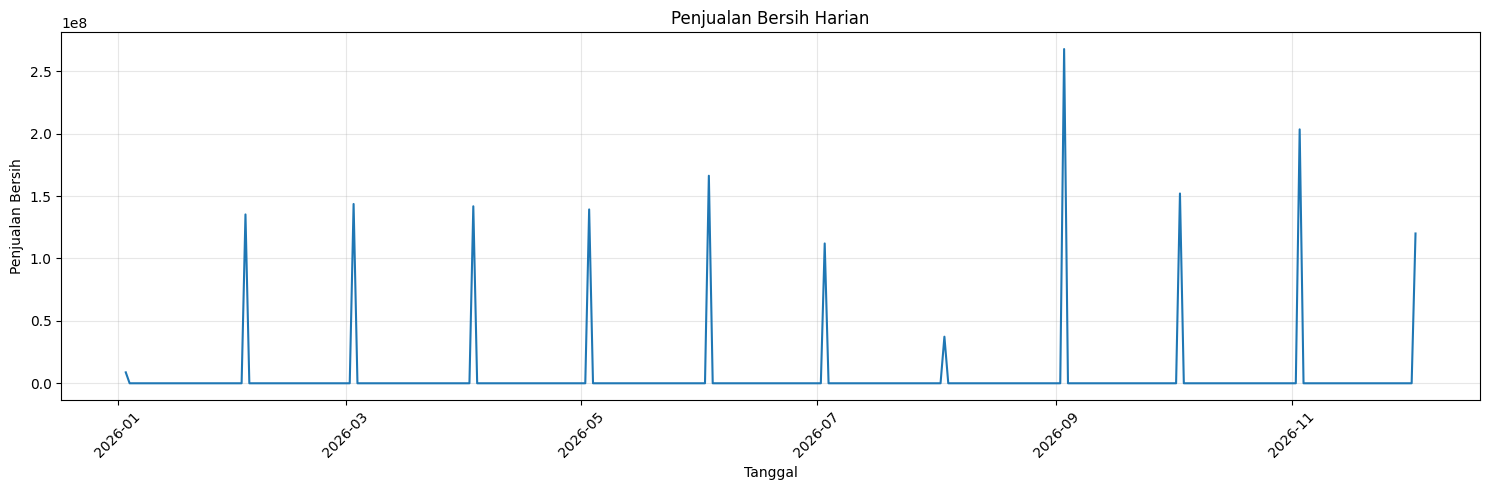

In [13]:
plt.figure(figsize=(15, 5))
plt.plot(daily["Tanggal"], daily["penjualan_bersih"], linewidth=1.5)
plt.title("Penjualan Bersih Harian")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan Bersih")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Pemeriksaan Ringkasan Time Series

In [14]:
target = daily.set_index("Tanggal")["penjualan_bersih"].asfreq("D")

print("Jumlah observasi:", target.shape[0])
print("Missing value pada target:", target.isna().sum())
print("Jumlah nilai nol:", int((target == 0).sum()))
print("Rata-rata penjualan harian:", target.mean())
print("Median penjualan harian:", target.median())
print("Standar deviasi:", target.std())
display(target.describe().to_frame("statistik_penjualan_bersih"))

Jumlah observasi: 335
Missing value pada target: 0
Jumlah nilai nol: 323
Rata-rata penjualan harian: 4860246.925373134
Median penjualan harian: 0.0
Standar deviasi: 28059938.062121786


,statistik_penjualan_bersih
count,3.350000e+02
mean,4.860247e+06
std,2.805994e+07
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,2.678646e+08


# Uji Stasioneritas Augmented Dickey-Fuller (ADF)

In [16]:
from statsmodels.tsa.stattools import adfuller

# Menggunakan variabel target dari preprocessing pertama
hasil_adf = adfuller(target, autolag="AIC")

print("HASIL UJI STASIONERITAS ADF")
print("=" * 45)
print(f"ADF Statistic : {hasil_adf[0]:.6f}")
print(f"p-value       : {hasil_adf[1]:.6f}")
print(f"Jumlah Lag    : {hasil_adf[2]}")
print(f"Jumlah Data   : {hasil_adf[3]}")

print("\nCritical Values:")
for key, value in hasil_adf[4].items():
    print(f"{key} : {value:.6f}")

if hasil_adf[1] < 0.05:
    print("\nKesimpulan: Data STASIONER")
    print("H0 ditolak karena p-value < 0.05")
else:
    print("\nKesimpulan: Data BELUM STASIONER")
    print("H0 gagal ditolak karena p-value >= 0.05")

HASIL UJI STASIONERITAS ADF
ADF Statistic : -18.281777
p-value       : 0.000000
Jumlah Lag    : 0
Jumlah Data   : 334

Critical Values:
1% : -3.450081
5% : -2.870233
10% : -2.571401

Kesimpulan: Data STASIONER
H0 ditolak karena p-value < 0.05


# Uji Stasioneritas Kwiatkowski-Phillips-Schmidt-Shin (KPSS)

In [17]:
from statsmodels.tsa.stattools import kpss

# Melakukan uji KPSS
hasil_kpss = kpss(target, regression="c", nlags="auto")

# Menampilkan hasil pengujian
print("HASIL UJI STASIONERITAS KPSS")
print("=" * 45)
print(f"KPSS Statistic : {hasil_kpss[0]:.6f}")
print(f"p-value        : {hasil_kpss[1]:.6f}")
print(f"Jumlah Lag     : {hasil_kpss[2]}")

print("\nCritical Values:")
for key, value in hasil_kpss[3].items():
    print(f"{key} : {value:.6f}")

# Kesimpulan
if hasil_kpss[1] > 0.05:
    print("\nKesimpulan: Data STASIONER")
    print("H0 gagal ditolak karena p-value > 0.05")
else:
    print("\nKesimpulan: Data BELUM STASIONER")
    print("H0 ditolak karena p-value <= 0.05")

HASIL UJI STASIONERITAS KPSS
KPSS Statistic : 0.055636
p-value        : 0.100000
Jumlah Lag     : 4

Critical Values:
10% : 0.347000
5% : 0.463000
2.5% : 0.574000
1% : 0.739000

Kesimpulan: Data STASIONER
H0 gagal ditolak karena p-value > 0.05


/tmp/ipykernel_1333/1634440929.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  hasil_kpss = kpss(target, regression="c", nlags="auto")


# Kesimpulan Uji Stasioneritas

In [18]:
# Mengambil hasil p-value
adf_pvalue = hasil_adf[1]
kpss_pvalue = hasil_kpss[1]

# Menentukan status stasioneritas
adf_stasioner = adf_pvalue < 0.05
kpss_stasioner = kpss_pvalue > 0.05

print("RINGKASAN HASIL UJI STASIONERITAS")
print("=" * 50)

print(f"ADF p-value  : {adf_pvalue:.6f}")
print(f"KPSS p-value : {kpss_pvalue:.6f}")

print("\nHASIL PENGUJIAN:")
print("ADF  :", "Stasioner" if adf_stasioner else "Tidak Stasioner")
print("KPSS :", "Stasioner" if kpss_stasioner else "Tidak Stasioner")

print("\nKESIMPULAN AKHIR:")

if adf_stasioner and kpss_stasioner:
    print("Data sudah STASIONER pada level.")
    print("Differencing nonmusiman awal yang disarankan: d = 0")

elif not adf_stasioner and not kpss_stasioner:
    print("Data BELUM STASIONER pada level.")
    print("Perlu dilakukan differencing nonmusiman.")

else:
    print("Hasil pengujian ADF dan KPSS berbeda.")
    print("Perlu pemeriksaan lebih lanjut sebelum menentukan differencing.")

RINGKASAN HASIL UJI STASIONERITAS
ADF p-value  : 0.000000
KPSS p-value : 0.100000

HASIL PENGUJIAN:
ADF  : Stasioner
KPSS : Stasioner

KESIMPULAN AKHIR:
Data sudah STASIONER pada level.
Differencing nonmusiman awal yang disarankan: d = 0
